# E-Commerce Product Analysis and Machine Learning

## Part 2: Classification and Machine Learning

This notebook focuses on building classification models to predict book rating categories using the cleaned Books to Scrape dataset.

### Objectives
- Prepare classification targets.
- Perform feature selection.
- Train classification algorithms.
- Evaluate and compare model performance.
- Perform cross-validation and hyperparameter tuning.
- Analyze feature importance.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# loading cleaned dataset

In [2]:
df = pd.read_csv("../data/books_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1000, 17)


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,51.77,3,In stock,22,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light i...,0.0,51.77,51.77,0,True,1017,6.925595,1017.0
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",0.0,53.74,53.74,0,True,1029,6.937314,1029.0
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,50.10,1,In stock,20,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un ...",0.0,50.10,50.10,0,True,1136,7.036148,1136.0
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",0.0,47.82,47.82,0,True,1647,7.407318,1647.0
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,54.23,5,In stock,20,History,4165285e1663650f,From a renowned historian comes a groundbreaki...,0.0,54.23,54.23,0,True,1969,7.585789,1969.0


# inspecting dataset

In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['title', 'product_url', 'price', 'star_rating', 'availability_status', 'stock_quantity', 'category', 'UPC', 'description', 'tax', 'price_excluding_tax', 'price_including_tax', 'number_of_reviews', 'has_description', 'description_length', 'description_length_log', 'description_length_capped']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   title                      1000 non-null   str    
 1   product_url                1000 non-null   str    
 2   price                      1000 non-null   float64
 3   star_rating                1000 non-null   int64  
 4   availability_status        1000 non-null   str    
 5   stock_quantity             1000 non-null   int64  
 6   category                   1000 non-null   str    
 7   UPC                        1000 non-null   str    
 8   descriptio

,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
count,1000,1000,1000.00000,1000.000000,1000,1000.000000,1000,1000,998,1000.0,1000.00000,1000.00000,1000.0,1000,1000.000000,1000.000000,1000.000000
unique,999,1000,NaN,NaN,1,NaN,50,1000,998,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN
top,The Star-Touched Queen,https://books.toscrape.com/catalogue/a-light-i...,NaN,NaN,In stock,NaN,Default,a897fe39b1053632,It's hard to imagine a world without A Light i...,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN
freq,2,1,NaN,NaN,1000,NaN,152,1,1,NaN,NaN,NaN,NaN,998,NaN,NaN,NaN
mean,NaN,NaN,35.07035,2.923000,NaN,8.585000,NaN,NaN,NaN,0.0,35.07035,35.07035,0.0,NaN,1441.449000,7.152067,1407.368375
std,NaN,NaN,14.44669,1.434967,NaN,5.654622,NaN,NaN,NaN,0.0,14.44669,14.44669,0.0,NaN,676.500121,0.608437,535.390181
min,NaN,NaN,10.00000,1.000000,NaN,1.000000,NaN,NaN,NaN,0.0,10.00000,10.00000,0.0,NaN,0.000000,0.000000,142.125000
25%,NaN,NaN,22.10750,2.000000,NaN,3.000000,NaN,NaN,NaN,0.0,22.10750,22.10750,0.0,NaN,1074.750000,6.980773,1074.750000
50%,NaN,NaN,35.98000,3.000000,NaN,7.000000,NaN,NaN,NaN,0.0,35.98000,35.98000,0.0,NaN,1353.500000,7.211188,1353.500000
75%,NaN,NaN,47.45750,4.000000,NaN,14.000000,NaN,NaN,NaN,0.0,47.45750,47.45750,0.0,NaN,1696.500000,7.436912,1696.500000



Missing Values:
title                        0
product_url                  0
price                        0
star_rating                  0
availability_status          0
stock_quantity               0
category                     0
UPC                          0
description                  2
tax                          0
price_excluding_tax          0
price_including_tax          0
number_of_reviews            0
has_description              0
description_length           0
description_length_log       0
description_length_capped    0
dtype: int64


## 2. Classification Target Preparation

The original star rating is converted into three categories:

- Low: 1 or 2 stars
- Medium: 3 stars
- High: 4 or 5 stars

This transforms the problem into a multiclass classification task.

In [4]:
df_ml = df.copy()

def assign_rating_class(rating):
    if rating <= 2:
        return "Low"
    elif rating == 3:
        return "Medium"
    else:
        return "High"

df_ml["rating_class"] = df_ml["star_rating"].apply(assign_rating_class)

df_ml[["star_rating", "rating_class"]].head(10)

,star_rating,rating_class
0,3,Medium
1,1,Low
2,1,Low
3,4,High
4,5,High
5,1,Low
6,4,High
7,3,Medium
8,4,High
9,1,Low


# checking class distribution

In [5]:
print("Rating Class Distribution:")
print(df_ml["rating_class"].value_counts())

print("\nPercentage Distribution:")
print(df_ml["rating_class"].value_counts(normalize=True) * 100)

Rating Class Distribution:
rating_class
Low       422
High      375
Medium    203
Name: count, dtype: int64

Percentage Distribution:
rating_class
Low       42.2
High      37.5
Medium    20.3
Name: proportion, dtype: float64


# visualizing the dataset
(important ,incase lo rating books are larger in amount ,it will imbalance our model training)

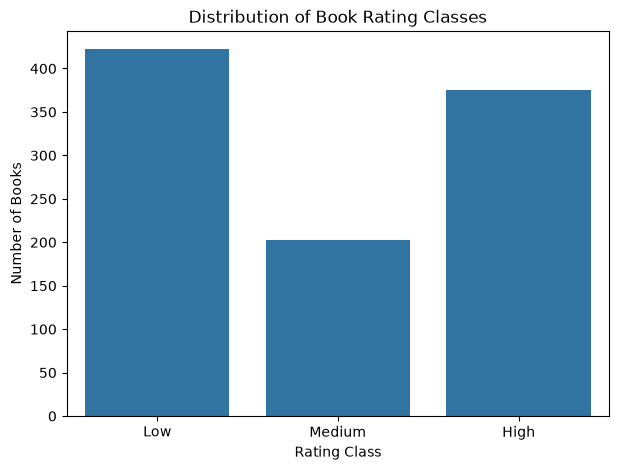

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_ml, x="rating_class", order=["Low", "Medium", "High"])

plt.title("Distribution of Book Rating Classes")
plt.xlabel("Rating Class")
plt.ylabel("Number of Books")
plt.show()

### Observations

1. The dataset contains 1,000 books.
2. Low-rated books represent 42.2% of the dataset.
3. Medium-rated books represent 20.3%.
4. High-rated books represent 37.5%.
5. The Medium class has the fewest observations.

The classes are not equally distributed. Therefore, stratified train-test splitting will be used to preserve the class proportions. Precision, recall and F1-score will also be considered during model evaluation.

## 4. Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

Stratified splitting is used to maintain the original distribution of rating classes in both sets.

A random state of 42 ensures reproducibility.

 ### 4.1 Feature and Target Selection

The target variable is `rating_class`, which contains three categories: Low, Medium, and High.

The input features selected initially are:

 Price
 Stock quantity
 Category
 Description availability
 Log-transformed description length

Identifiers, constant columns, redundant price columns, and the original star rating are excluded.

The original star rating is excluded because it was used to create the classification target. Including it would cause target leakage and produce misleading model performance.

These five features form our initial feature set. Forward Feature Selection and Backward Feature Elimination will later be used to identify useful features.

In [7]:
features = [
    "price",
    "stock_quantity",
    "category",
    "has_description",
    "description_length_log"
]

X = df_ml[features].copy()
y = df_ml["rating_class"].copy()

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
   price  stock_quantity            category  has_description  \
0  51.77              22              Poetry             True   
1  53.74              20  Historical Fiction             True   
2  50.10              20             Fiction             True   
3  47.82              20             Mystery             True   
4  54.23              20             History             True   

   description_length_log  
0                6.925595  
1                6.937314  
2                7.036148  
3                7.407318  
4                7.585789  

Target:
0    Medium
1       Low
2       Low
3      High
4      High
Name: rating_class, dtype: str

Feature Shape: (1000, 5)
Target Shape: (1000,)


### 4.2 Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

The `train_test_split()` function is used to perform this division.

Stratified sampling is applied because the three rating classes have different proportions. It maintains approximately the same class distribution in both training and testing datasets.

A random state of 42 is used to ensure reproducibility.

The training dataset is used for preprocessing, feature selection, and model training. The testing dataset is kept separate for final model evaluation.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 5)
Testing Features: (200, 5)

Training Target: (800,)
Testing Target: (200,)


In [9]:
print("Training Class Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Class Distribution:
rating_class
Low       42.25
High      37.50
Medium    20.25
Name: proportion, dtype: float64

Testing Class Distribution:
rating_class
Low       42.0
High      37.5
Medium    20.5
Name: proportion, dtype: float64


### Observations

The dataset was successfully divided into training and testing sets using an 80/20 split.

- The training dataset contains 800 books (80%).
- The testing dataset contains 200 books (20%).
- Stratified sampling maintained approximately the same proportions of Low, Medium, and High rating classes in both datasets.
- The class distribution in the training and testing sets is close to the original distribution.

Using stratification helps ensure that all three rating categories are adequately represented during model training and evaluation.

The training dataset will be used for preprocessing, feature selection, and model training, while the testing dataset will remain separate for final evaluation.

### 5. Feature Preprocessing

Before applying classification algorithms, the input features must be converted into a suitable numerical format.

The dataset contains numerical, categorical, and boolean features. We will use One-Hot Encoding to convert categorical features into numerical columns and StandardScaler to standardize numerical features.

Preprocessing will be fitted on the training data and then applied to the testing data to prevent data leakage.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "price",
    "stock_quantity",
    "description_length_log",
    "has_description"
]

categorical_features = ["category"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (800, 51)
Testing data shape: (200, 51)


### Observations

The preprocessing step was completed successfully.

- The training dataset contains 800 samples and 51 features.
- The testing dataset contains 200 samples and 51 features.
- StandardScaler was applied to numerical features.
- One-Hot Encoding converted the categorical category feature into numerical columns.
- The same preprocessing rules were applied to both training and testing datasets.

The resulting datasets are now in numerical format and ready for feature selection and classification model training.

### 6. Feature Selection

Feature selection helps identify the most relevant input features for a machine learning task. It can reduce unnecessary features, simplify the model, and potentially improve performance.

We will apply Forward Feature Selection and Backward Feature Elimination using Logistic Regression as the estimator. Macro F1-score will be used to evaluate feature combinations because the target contains three rating classes with different sample counts.

In [11]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

# Get the names of all preprocessed features
feature_names = preprocessor.get_feature_names_out()

# Create the classification estimator
estimator = LogisticRegression(max_iter=2000)

# Use 3-fold stratified cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Total available features:", len(feature_names))
print("Feature names:")
print(feature_names)

Total available features: 51
Feature names:
['num__price' 'num__stock_quantity' 'num__description_length_log'
 'num__has_description' 'cat__category_Academic'
 'cat__category_Add a comment' 'cat__category_Adult Fiction'
 'cat__category_Art' 'cat__category_Autobiography'
 'cat__category_Biography' 'cat__category_Business'
 'cat__category_Childrens' 'cat__category_Christian'
 'cat__category_Christian Fiction' 'cat__category_Classics'
 'cat__category_Contemporary' 'cat__category_Crime'
 'cat__category_Default' 'cat__category_Erotica' 'cat__category_Fantasy'
 'cat__category_Fiction' 'cat__category_Food and Drink'
 'cat__category_Health' 'cat__category_Historical'
 'cat__category_Historical Fiction' 'cat__category_History'
 'cat__category_Horror' 'cat__category_Humor' 'cat__category_Music'
 'cat__category_Mystery' 'cat__category_New Adult'
 'cat__category_Nonfiction' 'cat__category_Novels'
 'cat__category_Paranormal' 'cat__category_Philosophy'
 'cat__category_Poetry' 'cat__category_Politics

### 6.2 Forward Feature Selection

Forward Feature Selection starts with an empty set of features. It evaluates the available features and adds the most useful feature at each step.

We will select 10 features from the 51 available features using Logistic Regression and macro F1-score with 3-fold stratified cross-validation.

In [12]:
forward_selector = SequentialFeatureSelector(
    estimator=estimator,
    n_features_to_select=10,
    direction="forward",
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

forward_selector.fit(X_train_processed, y_train)

forward_features = feature_names[forward_selector.get_support()]

print("Selected features using Forward Selection:")
print(forward_features)

print("\nTotal selected features:", len(forward_features))

Selected features using Forward Selection:
['num__price' 'num__stock_quantity' 'cat__category_Childrens'
 'cat__category_Classics' 'cat__category_Default' 'cat__category_Mystery'
 'cat__category_Poetry' 'cat__category_Psychology' 'cat__category_Romance'
 'cat__category_Womens Fiction']

Total selected features: 10


### Observations

Forward Feature Selection successfully selected 10 features from the original 51 features.

The selected features include two numerical features (price and stock quantity) and eight category-related features.

This reduces the number of input features and provides a smaller feature set for classification. The selected features will be compared with those obtained through Backward Feature Elimination.

### 6.3 Backward Feature Elimination

Backward Feature Elimination starts with all available features and removes the least useful features step by step.

We will use Logistic Regression as the estimator, macro F1-score as the evaluation metric, and 3-fold stratified cross-validation. The process will continue until 10 features remain.

In [13]:
backward_selector = SequentialFeatureSelector(
    estimator=estimator,
    n_features_to_select=10,
    direction="backward",
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

backward_selector.fit(X_train_processed, y_train)

backward_features = feature_names[backward_selector.get_support()]

print("Selected features using Backward Elimination:")
print(backward_features)

print("\nTotal selected features:", len(backward_features))

Selected features using Backward Elimination:
['num__stock_quantity' 'cat__category_Christian Fiction'
 'cat__category_Default' 'cat__category_Fiction' 'cat__category_Humor'
 'cat__category_Mystery' 'cat__category_Poetry'
 'cat__category_Sequential Art' 'cat__category_Womens Fiction'
 'cat__category_Young Adult']

Total selected features: 10


In [14]:
print("Forward Selection Features:")
print(forward_features)

print("\nBackward Elimination Features:")
print(backward_features)

print("\nCommon Features:")
common_features = set(forward_features).intersection(set(backward_features))
print(common_features)

print("\nNumber of Common Features:", len(common_features))

Forward Selection Features:
['num__price' 'num__stock_quantity' 'cat__category_Childrens'
 'cat__category_Classics' 'cat__category_Default' 'cat__category_Mystery'
 'cat__category_Poetry' 'cat__category_Psychology' 'cat__category_Romance'
 'cat__category_Womens Fiction']

Backward Elimination Features:
['num__stock_quantity' 'cat__category_Christian Fiction'
 'cat__category_Default' 'cat__category_Fiction' 'cat__category_Humor'
 'cat__category_Mystery' 'cat__category_Poetry'
 'cat__category_Sequential Art' 'cat__category_Womens Fiction'
 'cat__category_Young Adult']

Common Features:
{'cat__category_Mystery', 'num__stock_quantity', 'cat__category_Womens Fiction', 'cat__category_Default', 'cat__category_Poetry'}

Number of Common Features: 5


### Comparison of Feature Selection Methods

Forward Feature Selection and Backward Feature Elimination were applied to identify useful features for classification.

Both methods selected 10 features. Their selected feature sets and common features were compared to understand whether the two approaches identified similar predictors.

The comparison helps us understand how feature selection strategy affects the choice of input features.

## 7. Classification Model Training

In this section, three classification algorithms are trained to predict whether a book belongs to the Low, Medium, or High rating category.

The selected features obtained through Forward Feature Selection will be used as input.

The models include:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

The models will be trained using the training dataset. Their performance will be evaluated later using the separate testing dataset.

In [15]:
# Select the features chosen by Forward Selection

X_train_selected = forward_selector.transform(X_train_processed)

X_test_selected = forward_selector.transform(X_test_processed)

print("Training data shape:", X_train_selected.shape)
print("Testing data shape:", X_test_selected.shape)

Training data shape: (800, 10)
Testing data shape: (200, 10)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create classification models

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Train all models

for name, model in models.items():
    model.fit(X_train_selected, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


### Observations

Three classification models were created and trained using the selected features obtained through Forward Feature Selection.

- Logistic Regression was used as a linear classification algorithm.
- Decision Tree was used to learn decision rules from the training data.
- Random Forest was used as an ensemble algorithm consisting of multiple decision trees.

All three models were trained using the 800 training samples and 10 selected features.

Their performance will be compared using classification evaluation metrics in the next section.

## 8. Classification Model Evaluation

In this section, the trained classification models are evaluated using the testing dataset.

The performance of each model is measured using accuracy, precision, recall, and F1-score. Confusion matrices and ROC curves are also used to understand their classification performance.

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

In [18]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test_selected)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro")
    recall = recall_score(y_test, y_pred, average="macro")
    f1 = f1_score(y_test, y_pred, average="macro")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)

results_df

C:\Users\LAPTOP SOLUTIONS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.38,0.246398,0.311111,0.265442
1,Decision Tree,0.33,0.308427,0.307104,0.307265
2,Random Forest,0.36,0.320904,0.322238,0.321489


### Observations

The three classification models achieved relatively low performance on the testing dataset.

- Logistic Regression achieved the highest accuracy of 38%.
- Random Forest achieved the highest macro F1-score of approximately 32.15%.
- Decision Tree achieved an accuracy of 33%.

The warning during precision calculation indicates that at least one model did not predict samples for one of the rating classes.

These results suggest that the selected features may not contain enough information to accurately distinguish between all three rating categories. Further evaluation and model tuning are required.

## confusion Matrices 
Show correct and incorrect predictions for each class

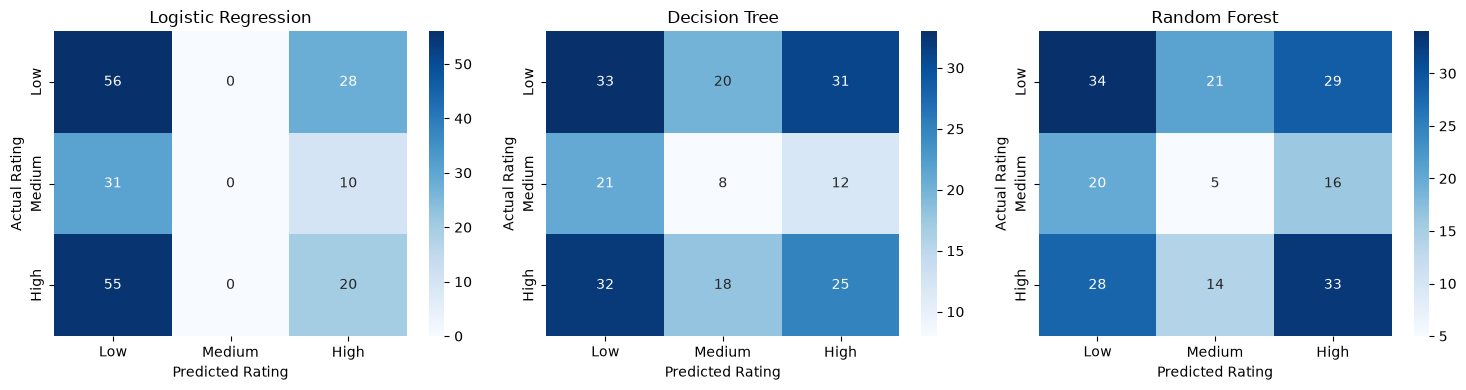

In [19]:
class_labels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test_selected)

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Rating")
    ax.set_ylabel("Actual Rating")

plt.tight_layout()
plt.show()

### Observations

The confusion matrices provide a detailed view of the correct and incorrect predictions made by each classification model.

- **Logistic Regression:** Correctly classified 56 Low-rated and 20 High-rated books. However, it failed to predict any Medium-rated books.
- **Decision Tree:** Correctly classified 33 Low-rated, 8 Medium-rated, and 25 High-rated books. It made several incorrect predictions across all three classes.
- **Random Forest:** Correctly classified 34 Low-rated, 5 Medium-rated, and 33 High-rated books. It performed better in identifying Low and High classes than Medium.

Overall, all three models struggled to distinguish between the rating categories, particularly the Medium class. The confusion matrices support the relatively low evaluation scores observed earlier.

## classification Report
examine precision, recall, and F1-score separately for each class (Low, Medium, High) to understand exactly which rating categories each model struggles to predict

In [20]:
for name, model in models.items():

    y_pred = model.predict(X_test_selected)

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

         Low       0.39      0.67      0.50        84
      Medium       0.00      0.00      0.00        41
        High       0.34      0.27      0.30        75

    accuracy                           0.38       200
   macro avg       0.25      0.31      0.27       200
weighted avg       0.29      0.38      0.32       200


 Decision Tree
              precision    recall  f1-score   support

         Low       0.38      0.39      0.39        84
      Medium       0.17      0.20      0.18        41
        High       0.37      0.33      0.35        75

    accuracy                           0.33       200
   macro avg       0.31      0.31      0.31       200
weighted avg       0.33      0.33      0.33       200


 Random Forest
              precision    recall  f1-score   support

         Low       0.41      0.40      0.41        84
      Medium       0.12      0.12      0.12        41
        High       0.

### Observations

The classification reports provide precision, recall, and F1-scores for each rating category.

- **Logistic Regression** achieved the highest F1-score for the Low class (0.50). However, it failed to identify Medium-rated books, resulting in an F1-score of 0.00 for this class.
- **Decision Tree** identified all three rating categories but achieved relatively low F1-scores.
- **Random Forest** achieved the highest macro F1-score (0.32) among the three models and performed best for the High class with an F1-score of 0.43.
- All three models struggled to classify Medium-rated books correctly.

Overall, Random Forest performed slightly better in terms of macro F1-score, while Logistic Regression achieved the highest accuracy of 38%. However, the overall performance of all three models was relatively low, indicating difficulty in distinguishing between rating categories.

 ## ROC Curves and AUC – 
One-vs-Rest ROC curves and Macro AUC

In [21]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

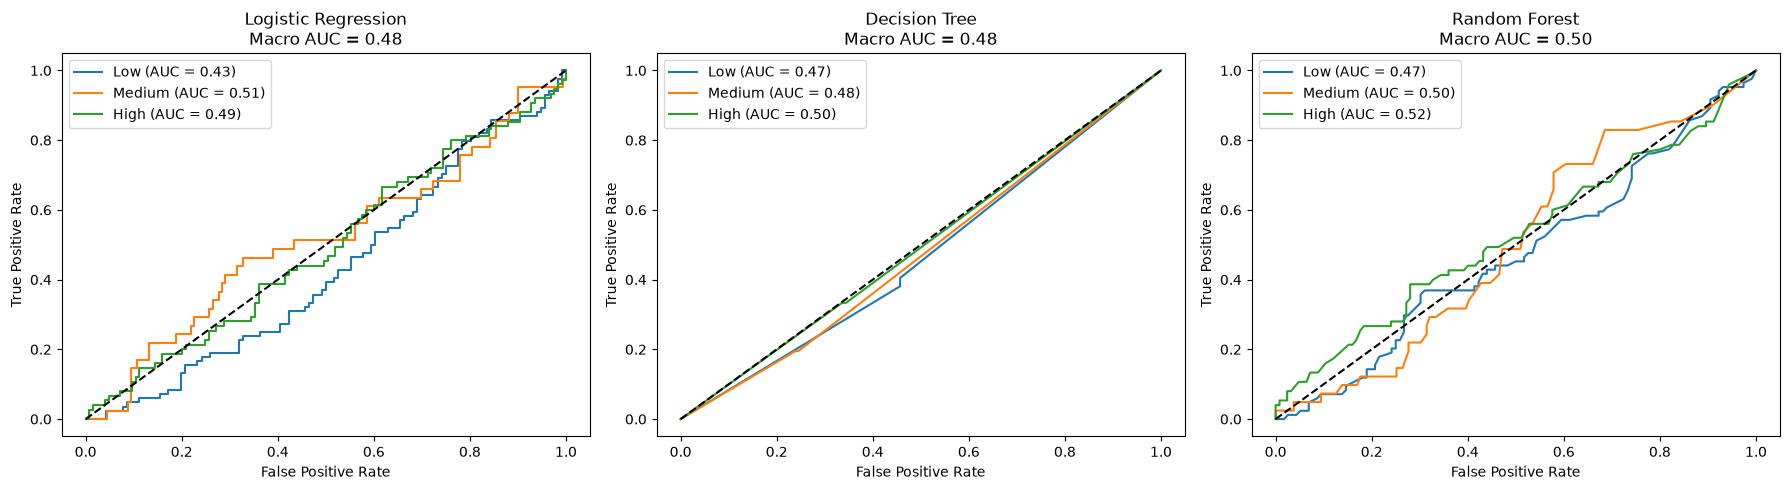

In [22]:
class_labels = ["Low", "Medium", "High"]

# Convert actual classes into binary format
y_test_bin = label_binarize(y_test, classes=class_labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

roc_results = []

for ax, (name, model) in zip(axes, models.items()):

    # Get predicted probabilities
    y_score = model.predict_proba(X_test_selected)

    # Arrange probability columns in the same order as class_labels
    model_classes = list(model.classes_)
    y_score = y_score[:, [model_classes.index(c) for c in class_labels]]

    class_aucs = []

    # Calculate ROC curve for each class
    for i, class_name in enumerate(class_labels):

        fpr, tpr, thresholds = roc_curve(
            y_test_bin[:, i],
            y_score[:, i]
        )

        class_auc = auc(fpr, tpr)
        class_aucs.append(class_auc)

        ax.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {class_auc:.2f})"
        )

    # Calculate Macro AUC
    macro_auc = np.mean(class_aucs)

    roc_results.append({
        "Model": name,
        "Macro AUC": macro_auc
    })

    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"{name}\nMacro AUC = {macro_auc:.2f}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.tight_layout()
plt.show()

In [23]:
roc_results_df = pd.DataFrame(roc_results)
roc_results_df

,Model,Macro AUC
0,Logistic Regression,0.477585
1,Decision Tree,0.480009
2,Random Forest,0.498124


### Observations

The One-vs-Rest ROC curves and Macro AUC scores were used to evaluate how effectively the models distinguish between Low, Medium, and High rating classes.

- **Logistic Regression** achieved a Macro AUC of approximately 0.478.
- **Decision Tree** achieved a Macro AUC of approximately 0.480.
- **Random Forest** achieved the highest Macro AUC of approximately 0.498.

All three models produced Macro AUC scores close to 0.50, indicating weak class-discrimination ability.

Random Forest performed slightly better than the other models, but the overall results suggest that the selected features do not provide sufficient information for reliable rating classification.